<a href="https://colab.research.google.com/github/TiagoNonohay/pump_monitoring/blob/main/Monitoramento_de_Bomba_Centr%C3%ADfuga.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12 entries, 2026-11-03 10:00:00+00:00 to 2026-11-03 10:55:00+00:00
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   temperatura_c     12 non-null     float64
 1   vibracao_mms_rms  12 non-null     float64
 2   pressao_bar       12 non-null     float64
 3   estado            12 non-null     object 
 4   vibration_status  12 non-null     object 
dtypes: float64(3), object(2)
memory usage: 576.0+ bytes
None

--- First Rows ---
                           temperatura_c  vibracao_mms_rms  pressao_bar  \
timestamp                                                                 
2026-11-03 10:00:00+00:00           42.1               1.8          3.2   
2026-11-03 10:05:00+00:00           42.3               1.9          3.2   
2026-11-03 10:10:00+00:00           42.4               2.0          3.1   
2026-11-03 10:15:00+00:00         

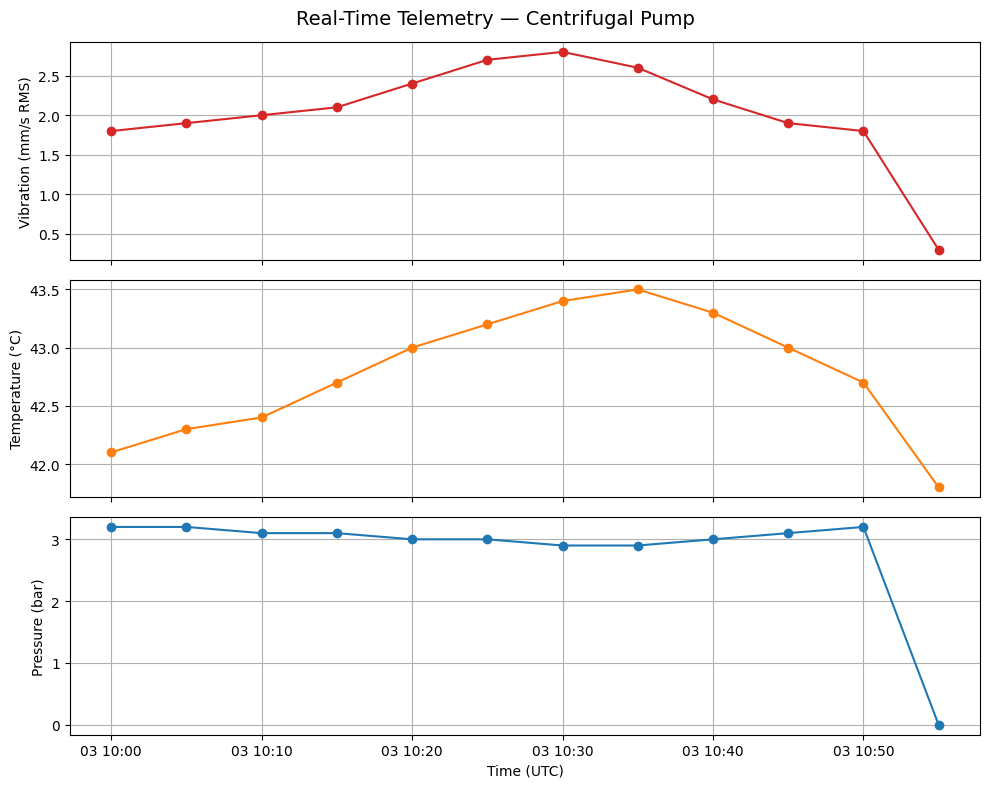

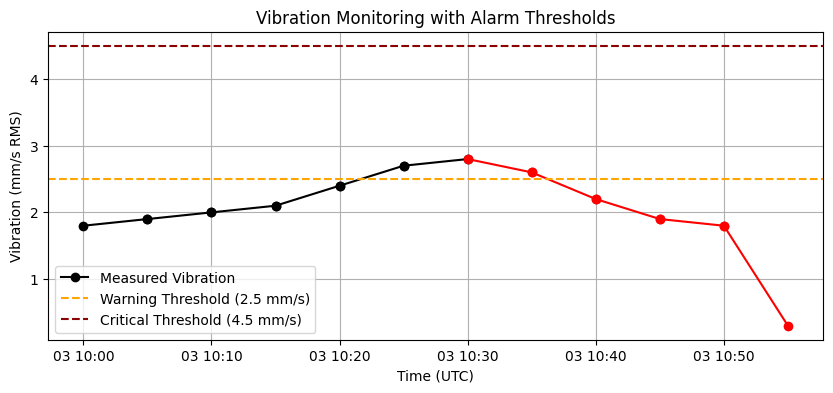

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

def classify_vibration(vibration, status):
    if status == 'STOPPED': return 'STOPPED'
    if vibration > 4.5: return 'CRITICAL'
    if vibration > 2.5: return 'WARNING'
    return 'NORMAL'

url = "https://raw.githubusercontent.com/TiagoNonohay/pump_monitoring/main/simulated_telemetry.csv"
df = pd.read_csv(url, parse_dates=['timestamp'], index_col='timestamp')

df['vibration_status'] = df.apply(lambda row: classify_vibration(row['vibracao_mms_rms'], row['estado']), axis=1)
df_running = df[df['estado'] == 'RUNNING']
analysis_cols = ['vibracao_mms_rms', 'temperatura_c', 'pressao_bar']

print("--- Dataset Information ---")
print(df.info())
print("\n--- First Rows ---")
print(df.head())
print("\n--- Descriptive Statistics (Normal Operation) ---")
print(df_running[analysis_cols].describe().round(2))
print("\n--- Correlation Matrix ---")
print(df_running[analysis_cols].corr().round(2))
print("\n--- Vibration Alert Distribution ---")
print(df['vibration_status'].value_counts())

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
colors = ['tab:red', 'tab:orange', 'tab:blue']
labels = ['Vibration (mm/s RMS)', 'Temperature (°C)', 'Pressure (bar)']

for ax, col, color, ylabel in zip(axs, analysis_cols, colors, labels):
    ax.plot(df.index, df[col], color=color, marker='o')
    ax.set_ylabel(ylabel)
    ax.grid(True)

plt.xlabel('Time (UTC)')
plt.suptitle('Real-Time Telemetry — Centrifugal Pump', fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
values = df['vibracao_mms_rms']
timestamps = df.index

for i in range(1, len(df)):
    x_seg = timestamps[i-1:i+1]
    y_seg = values.iloc[i-1:i+1]
    color = 'red' if y_seg.iloc[1] < y_seg.iloc[0] else 'black'
    legend = 'Measured Vibration' if i == 1 else ""
    plt.plot(x_seg, y_seg, marker='o', color=color, label=legend)

plt.axhline(y=2.5, color='orange', linestyle='--', label='Warning Threshold (2.5 mm/s)')
plt.axhline(y=4.5, color='darkred', linestyle='--', label='Critical Threshold (4.5 mm/s)')
plt.title('Vibration Monitoring with Alarm Thresholds')
plt.ylabel('Vibration (mm/s RMS)')
plt.xlabel('Time (UTC)')
plt.legend()
plt.grid(True)
plt.show()